In [ ]:
# This code is an all-purpose tool for viewing meteorological fields surrounding a given point on a 
# given date. 

In [1]:
# Import modules
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy as cart
from cartopy import crs as ccrs, feature as cfeature

In [2]:
parent_data_directory = '/g/data/w40/nxg561/ERA5/'

In [3]:
# write the data extraction and plotting code as modular functions

def extract_xr_data_centered(data_dir, var_name, y, m, d, h, levels, lat, lon, radius):

    '''This code extracts an xarray data_array of a variable with width equal to a radius either side
    of a central point lat/lon. Output is a dictionary of data_arrays, and a list of keys to access that dictionary.'''

    # set an empty dictionary to contain the data to plot
    data_dict = {}
    dict_keys = []

    # the filename is constructed from the year and month. CHANGE THIS LINE FOR DIFFERENT FILE NAME PATTERNS AND DIRECTORY
    # STRUCTURES
    filename = 'z_era5_oper_pl_' + str(y) + str(m).zfill(2) + '.nc'
    
    # open the dataset and extract the field to plot
    ds = xr.open_dataset(data_dir + filename, engine='netcdf4')
        
    # Create datetime object
    target_time = pd.Timestamp(year=y, month=m, day=d, hour=h)
    
    # loop through the levels and extract the fields to plot
    for level in levels:
        
        # Select data at this time
        data = ds[var_name].sel(time=target_time, level=level, 
                                lat=slice(lat+radius, lat-radius), 
                                lon=slice(lon-radius, lon+radius))
        data = data / 9.8 # convert geopotential to gpm
    
        # add the data to the dictionary
        data_dict[level] = data
        dict_keys.append(level)

    return data_dict, dict_keys

def extract_xr_data_full(data_dir, var_name, y, m, d, h, levels):

    '''This code extracts an xarray data_array of a variable across the whole dataset extent. 
    Output is a dictionary of data_arrays, and a list of keys to access that dictionary.'''

    # set an empty dictionary to contain the data to plot
    data_dict = {}
    dict_keys = []

    # the filename is constructed from the year and month. CHANGE THIS LINE FOR DIFFERENT FILE NAME PATTERNS AND DIRECTORY
    # STRUCTURES
    filename = 'z_era5_oper_pl_' + str(y) + str(m).zfill(2) + '.nc'
    
    # open the dataset and extract the field to plot
    ds = xr.open_dataset(data_dir + filename, engine='netcdf4')
        
    # Create datetime object
    target_time = pd.Timestamp(year=y, month=m, day=d, hour=h)
    
    # loop through the levels and extract the fields to plot
    for level in levels:
        
        # Select data at this time
        data = ds[var_name].sel(time=target_time, level=level)
        data = data / 9.8 # convert geopotential to gpm
    
        # add the data to the dictionary
        data_dict[level] = data
        dict_keys.append(level)

    return data_dict, dict_keys

def plot_synoptic_fields(data_dict, dict_keys, levels):

    '''This function plots contour plots of the xarray data_arrays contained in the input dictionaries. '''

    # the number of levels will be used to define the size of the figure and number the figure axes
    nlevs = len(levels)

    # Set a projection for the maps
    proj = ccrs.PlateCarree()
    
    # Create figure with a panel for each of the levels specified
    fig, axes = plt.subplots(nlevs, 1, figsize=(18, nlevs*6), subplot_kw={"projection": proj}, constrained_layout=True)
    
    # Flatten axes array for easy iteration
    axes = axes.ravel()
    
    for i, ax in enumerate(axes):
    
        # get the rainfall array for this filter out of the dictionary
        key = dict_keys[i]
        plot_data = data_dict[key]
        plot_time = plot_data.time.data
    
        ax.set_title(str(key) + ' hPa level Geopotential Height, ' + str(plot_time), fontsize=15, fontweight='bold', y=1.1)
    
        dataplot = ax.contour(plot_data['lon'], plot_data['lat'], plot_data, levels=20)
        
        # add a map underlay 
        ax.coastlines()
        gl = ax.gridlines(draw_labels=True, linewidth=1, color='gray', alpha=1, linestyle = '--')
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {'size':12}
        gl.ylabel_style = {'size':12}

    return

def plot_date_hemisphere(data_dir, var_name, y, m, d, h, levels):

    '''This code calls the pre-defined functions for extracting data_arrays of netcdf data for a given date and plotting it
    across the whole extent of the dataset. '''

    data_dict, dict_keys = extract_xr_data_full(data_dir, var_name, y, m, d, h, levels)

    fig = plot_synoptic_fields(data_dict, dict_keys, levels)

    return fig

def plot_date_subset(data_dir, var_name, y, m, d, h, levels, lat, lon, radius=15):

    '''This code calls the pre-defined functions for extracting data_arrays of netcdf data centered on a specified point
    for a given date and plotting it across the subset. '''

    data_dict, dict_keys = extract_xr_data_centered(data_dir, var_name, y, m, d, h, levels, lat, lon, radius)

    fig = plot_synoptic_fields(data_dict, dict_keys, levels)

    return fig

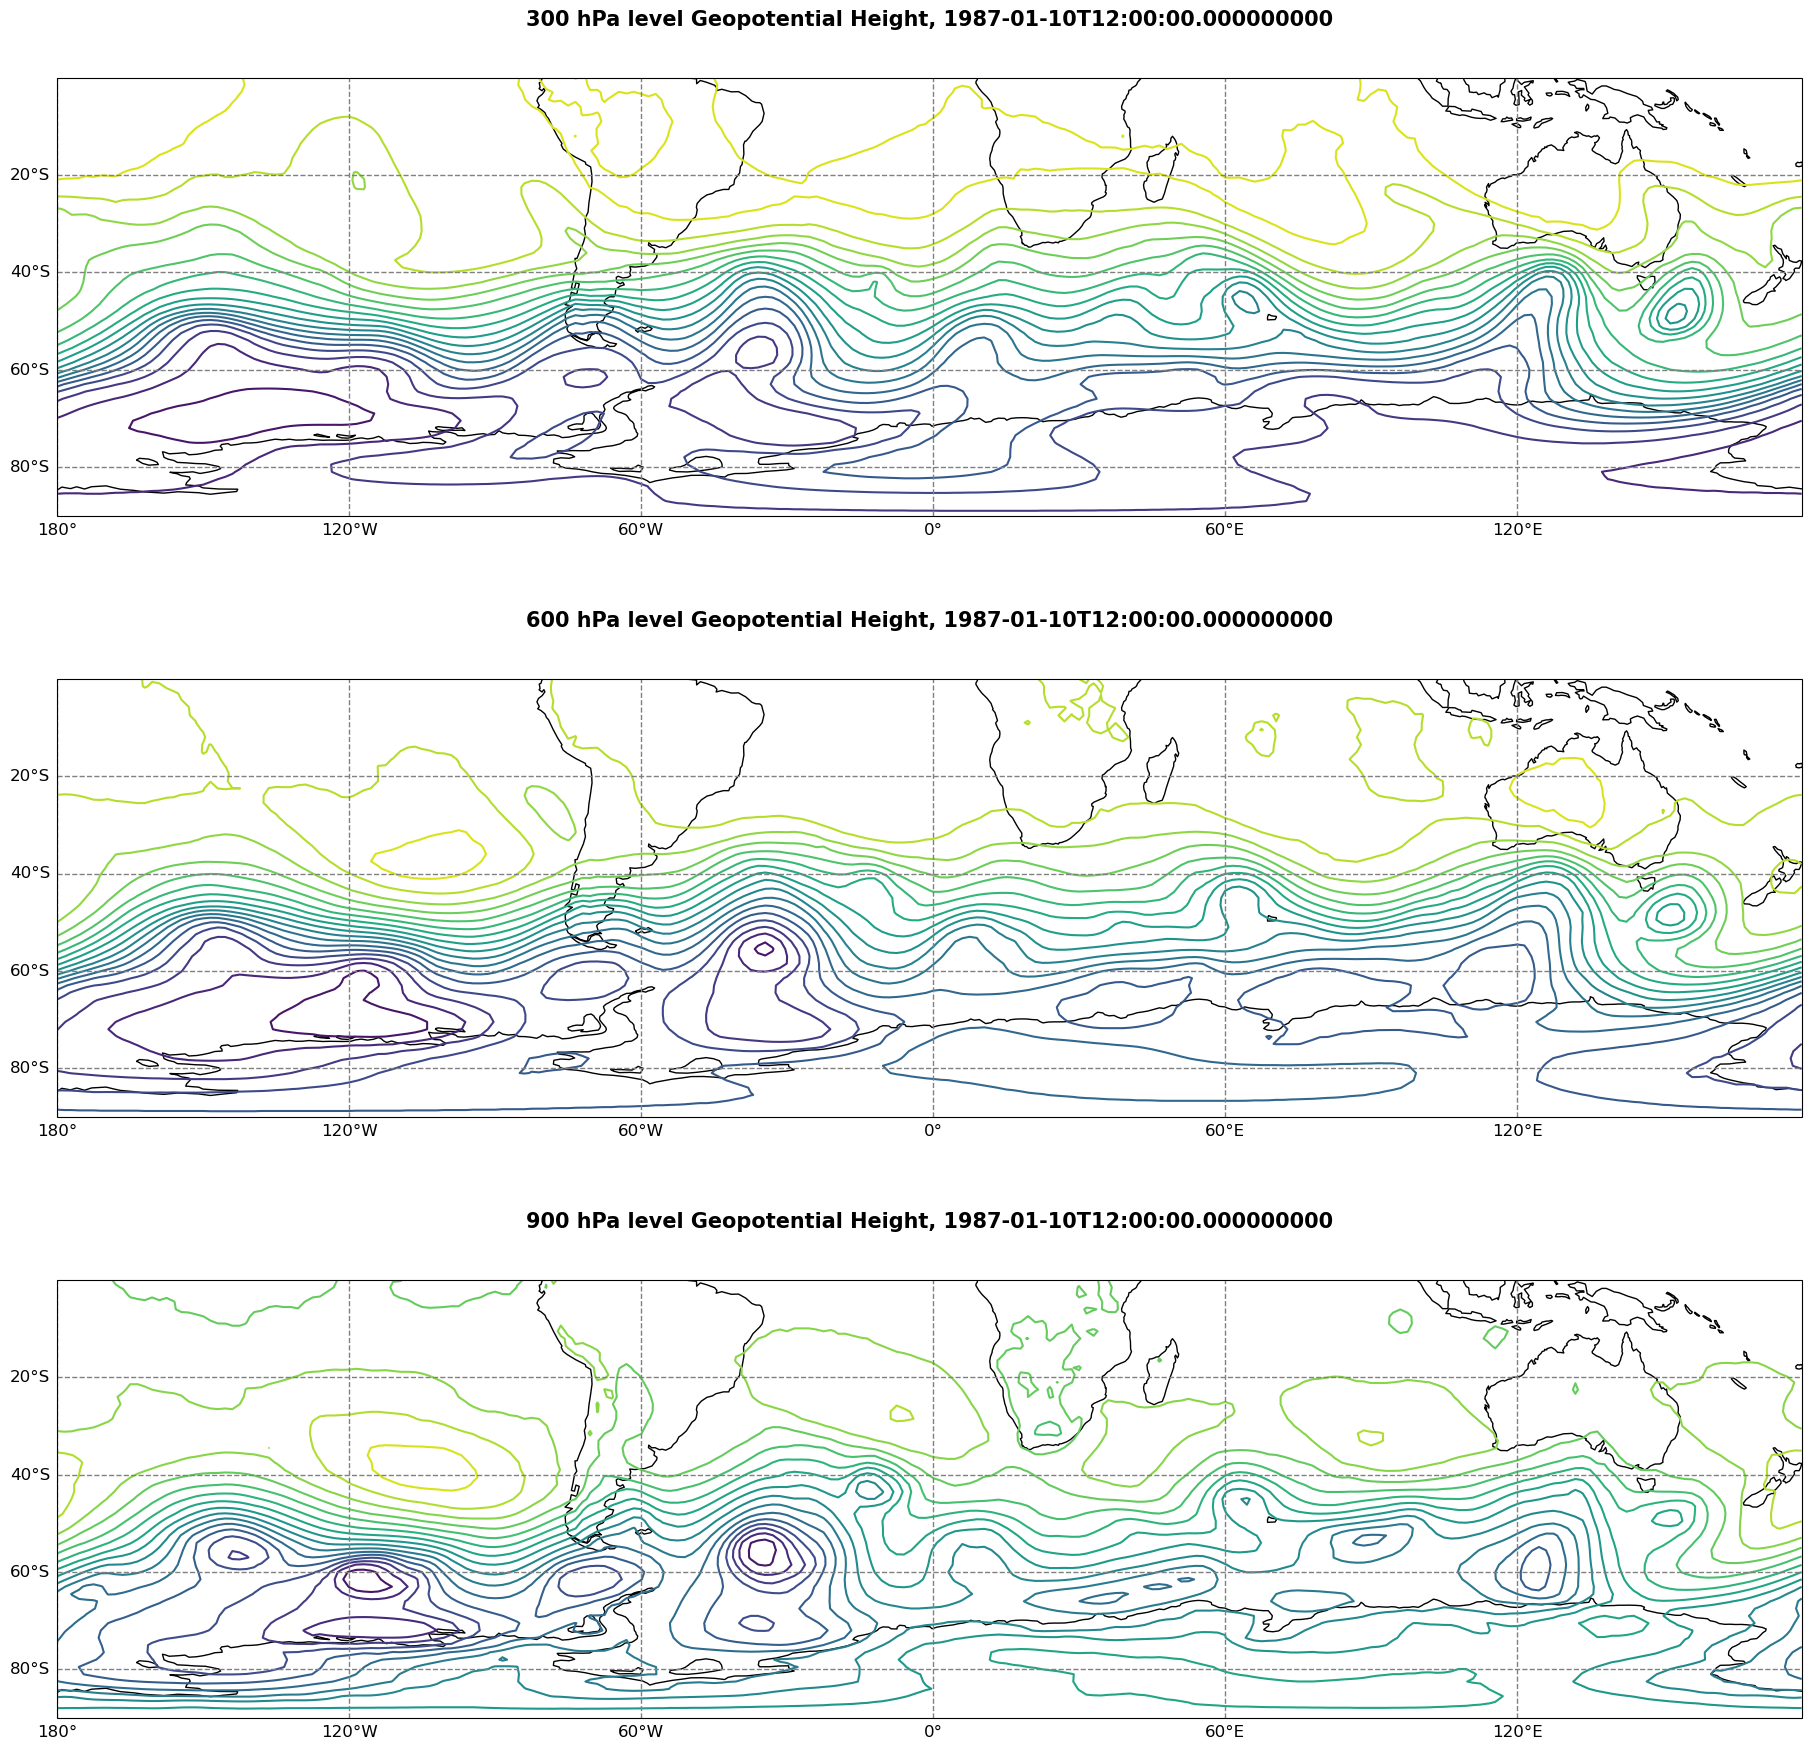

In [4]:
# test the whole hemisphere function
fig = plot_date_hemisphere(parent_data_directory, 'z', 1987, 1, 10, 12, (300, 600, 900))

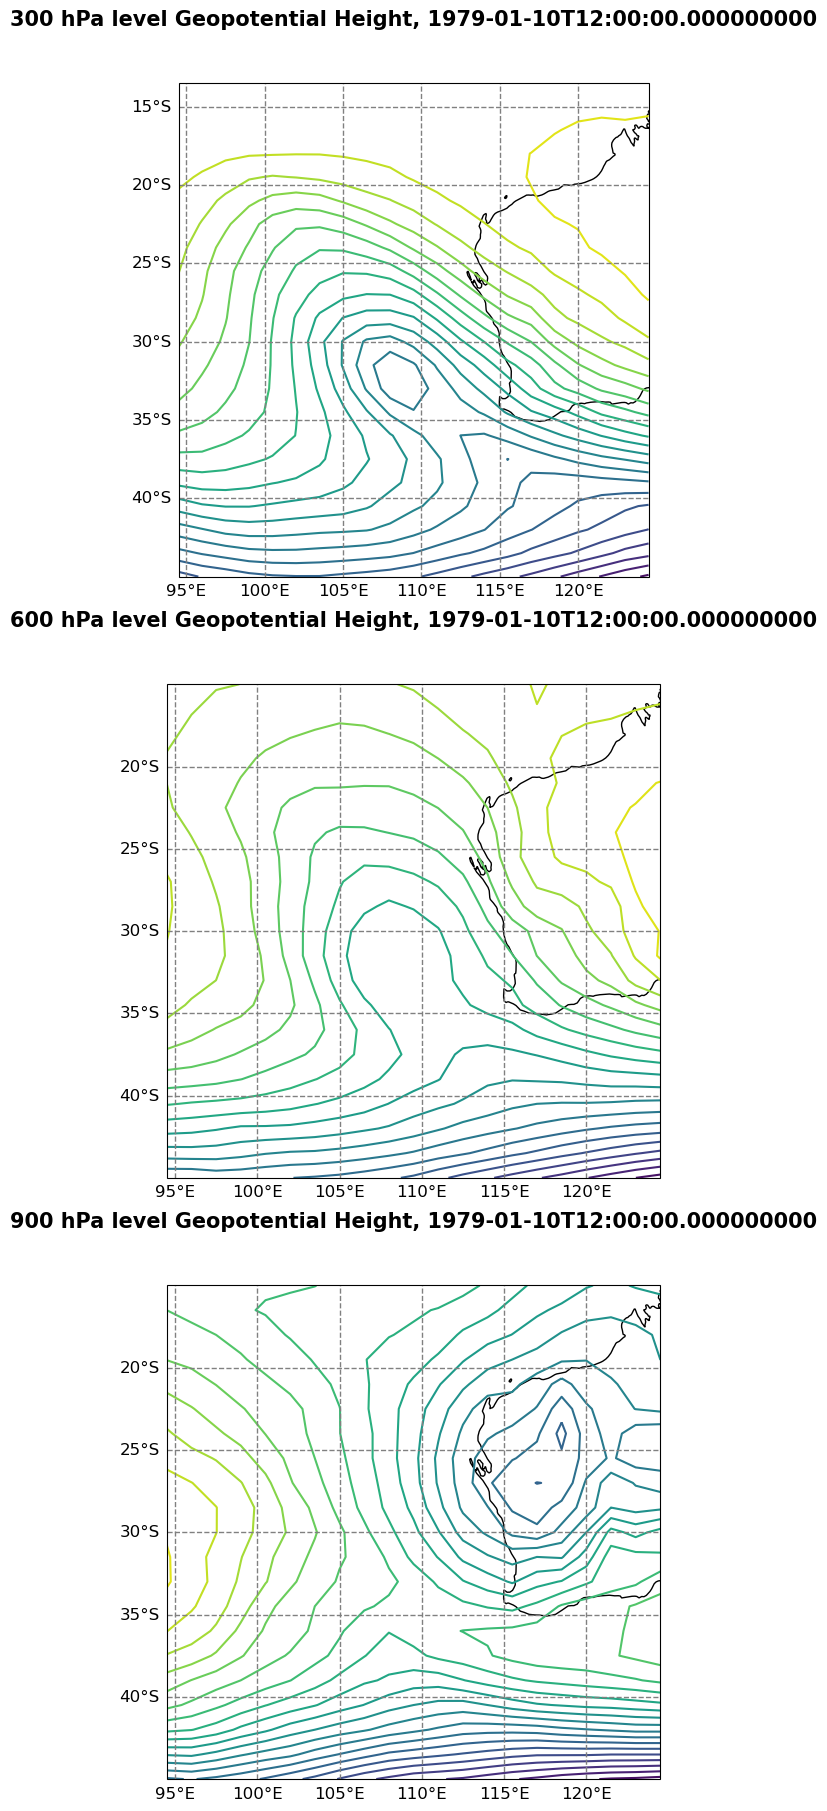

In [5]:
# test the subset function
plot_date_subset(parent_data_directory, 'z', 1979, 1, 10, 12, (300, 600, 900), -30, 109.5, radius=15)

In [11]:
# save any output figures
save_dir = '/g/data/m35/nxg561/'
file_name = 'synoptic_test.png'
fig.savefig(save_dir + file_name, format='png')

AttributeError: 'NoneType' object has no attribute 'savefig'